
<table>
    <tr>
        <td><img src='https://coastalrisk.live/wp-content/uploads/2018/05/cera_50x50.png' alt='Image' width='50' height=50'></td>
        <td><h1 align="left"><font color='green'>Geospatial Data Visualization: Introduction to Cartopy </font></h1></td>
    </tr>
</table>


In [2]:
# Copyright (C): Carola Kaiser 2014-2024, Louisiana State University. 
# This script is part of the Coastal Emergency Risks Assessment (CERA), a real-time visualization system for storm surge guidance.
# See https://cera.coastalrisk.live. This CERA script is Open Source software; distributed under the MIT License.

## 1.2 - Tutorial example csv file
In our exercise, we will use a point data file in the comma-separated text format (csv) that contains three water level stations.
If you do not have the 'wget' tool installed, you can download the file by adding the URL in a web browser.


In [3]:
from pathlib import Path
from urllib.request import urlretrieve

csv_file = Path("water_level_stations.csv")
if csv_file.exists():
    print(f"{csv_file} already exists; skipping download.")
else:
    urlretrieve(
        "https://cloud.cera.lsu.edu/s/6qamYSWn2FarbLP/download/water_level_stations.csv",
        csv_file,
    )
    print(f"Downloaded {csv_file}.")

water_level_stations.csv already exists; skipping download.


## 1.3 - Importing the Python libraries

In [4]:
"""
This script demonstrates the usage of Cartopy and Matplotlib libraries for data visualization.

The script imports the necessary libraries, including Cartopy, Matplotlib, and numpy, for data handling and visualization.
It also sets up the necessary configurations and filters out warnings for the purpose of this tutorial.
"""

# Cartopy/Matplotlib libraries
import cartopy.feature as cfeature
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.image as image
from matplotlib.offsetbox import (AnnotationBbox, OffsetImage, TextArea)

# libraries for data handling
import numpy as np
import netCDF4
import pandas as pd

# libraries for url image fetching 
import urllib.request
from PIL import Image

# For the purposes of this tutorial, we'll be ignoring warnings from functions
import warnings
warnings.filterwarnings('ignore')

# widgets library
import ipywidgets 
from ipywidgets import Layout, interact, IntSlider, FloatSlider

# Part 2: Map Visualization

## 2.1 - Understanding the Matplotlib Plot Structure
Cartopy works with the Python Matplolib library. In order to make the most out of Cartopy, it is useful to have a general understanding of the Matplotlib/PypPlot graphics structure.

A Matplotlib plot can be configured in several ways, depending on the complexity of the final plot. In this tutorial, we will use a basic single plot.

### Basic elements of a Matplotlib plot
The outermost container of a Matplotlib graphics is called Figure. A figure holds several sub-elements like the data visualization area (Axes), titles, colorbars etc. 

When we draw a plot using Matplotlib Pyplot, a Figure object is generated (shown in red).
An Axes object is generated within the Figure object, including the x and y-axis (shown in green).
The “axes” object holds all objects with plotting methods like graphs or contouring results. The surrounding “figure” defines the final image and additionally contains elements like the colorbar.

For one plot (without any customization), the “ax” and “fig” can be seen as identical.

<p><img src="https://cloud.cera.lsu.edu/s/kktwmeN9k927eiH/download/fig_ax.png" width="400"></p>

## 2.2 - Creating a basic map with Cartopy

Creating a basic map is an easy step: We simply tell Matplotlib to use a specific map projection and add some coastlines to the map.

- The Cartopy `map projections` are stored in the module `cartopy.crs` that we have imported with the alias name `ccrs`. 

    Cartopy supports several cartographic projections like Mercator, PlateCarree, LambertConformal, AlbersEqualArea, Orthographic, Mollweide, and more. A list of all available projections can be found on the Cartopy [projection](https://scitools.org.uk/cartopy/docs/v0.15/crs/projections.html#cartopy-projections) list page.
- The Cartopy `feature` interface allows to add pre-defined Natural Earth datasets, like coastlines, ocean, land, etc. We have imported the module `cartopy.feature` with the alias name `cfeature`. 

    When adding the coastline feature without any arguments, Cartopy will add the Natural Earth 1:110,000,000 scale coastline data to the map. A full list of supported features can be found on the Cartopy [feature](https://scitools.org.uk/cartopy/docs/latest/matplotlib/feature_interface.html) list page.

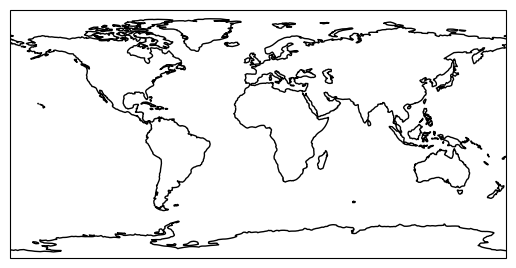

In [5]:
# set the map projection
ax = plt.axes(projection=ccrs.PlateCarree()) 

# add the coastline feature
ax.add_feature(cfeature.COASTLINE)

plt.show()


The first line of code is creating a map with the Plate Carrée projection (also known as Equirectangular projection or Geographic projection). This projection maps meridians to vertical straight lines of constant spacing, and circles of latitude to horizontal straight lines of constant spacing. The result is a 'grid' where the gridlines are equally spaced apart. This is stored in the variable `ax`.

The second line of code is adding a coastline feature to the map. This will draw the outline of continents and major islands on the map.

The same map in the Mollweide projection with the center of the map set to North/South America.

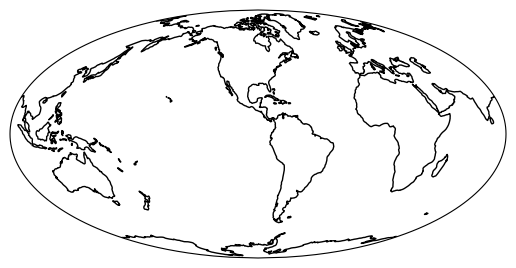

In [6]:
ax = plt.axes(projection=ccrs.Mollweide(central_longitude=-90))
ax.add_feature(cfeature.COASTLINE)
plt.show()

## 2.3 - Adding a background image and customizing the coastline feature

We can use the stock_img() method to add an underlaying image to the map that shows some terrain and seafloor information.

The overlaid coastline can be customized in many ways, e.g. by adding 
- a line style (like 'dotted', 'dashed' etc.)
- a line width (with 1 being the default value)
- a color (hexadecimal color code like '#FF0000', color name 'red', or short annotation 'r')

For full information of styling options, please use the Matplotlib documentation.

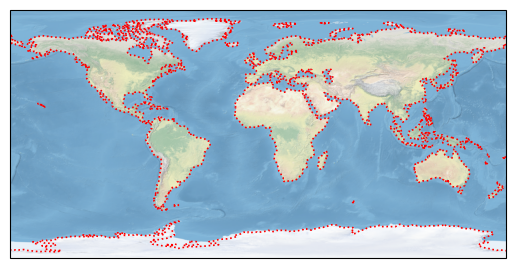

In [7]:
# set the map projection
ax = plt.axes(projection=ccrs.PlateCarree())

# add the coastline feature and customize its style
ax.add_feature(cfeature.COASTLINE, linestyle='dotted', linewidth=1.2, color='red')

# add a background map image
ax.stock_img()

plt.show()

The second line in the code is adding a coastline feature with a customized style. As an example, we are using dotted line style, a line width of 1.2, and a red color. This will draw the outline of continents and major islands on the map in a red, dotted line.

The third line of code is adding a background map image. The `ax.stock_img()` function call is adding a low-resolution Natural Earth background image to the map. This will give the map a more realistic appearance.

## 2.4 - Creating a regional map
In order to create a regional map, we use the Cartopy `set_extent` method to limit the size of the region. 

Additionally, we can increase the `resolution` of the displayed coastline. Supported values are '110m' (default), '50m', '10m'.

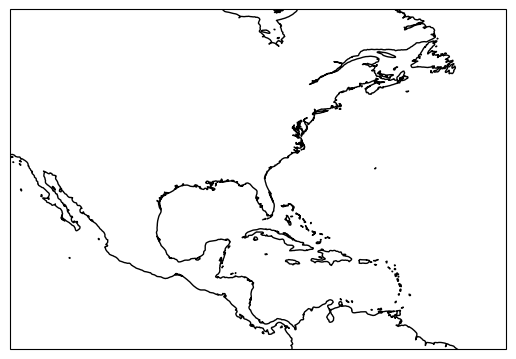

In [8]:
# set the map projection
ax = plt.axes(projection=ccrs.PlateCarree())

# assign a bounding box as map extent
ax.set_extent([-45, -120, 5, 50])

# set a higher resolution for the coastline
ax.add_feature(cfeature.COASTLINE.with_scale('50m'))

plt.show()

The second line of code is setting the extent of the map to the coordinate ranges -45 to -120 on the x-axis (longitude) and 5 to 50 on the y-axis (latitude). This will limit the map to only show the area within these coordinates.

The third line of code is adding a coastline feature to the map with a resolution of 50 meters. This will draw the outline of continents and major islands on the map with a higher level of detail.

## 2.5 - Enriching the Map

Next, we can add some some more built-in Natural Earth features. As with the coastline, Cartopy uses default colors and line styles that can later be customized. For consistency of the features, we will apply the same resolution to all features.

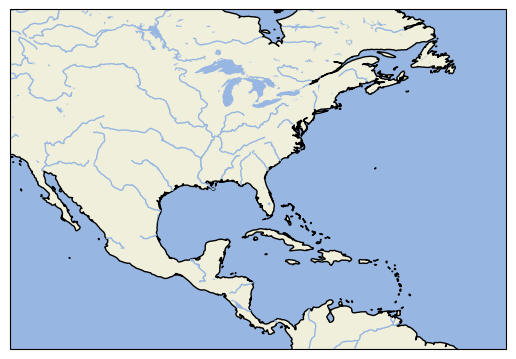

In [9]:
# set the map projection and map extent
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-45, -120, 5, 50])

# add features
ax.add_feature(cfeature.COASTLINE.with_scale('50m'))
ax.add_feature(cfeature.OCEAN.with_scale('50m'))
ax.add_feature(cfeature.LAND.with_scale('50m'))
#ax.add_feature(cfeature.STATES.with_scale('50m')) # U.S. state borders
ax.add_feature(cfeature.LAKES.with_scale('50m'))
ax.add_feature(cfeature.RIVERS.with_scale('50m'))
#ax.add_feature(cfeature.BORDERS.with_scale('50m')) # country borders

plt.show()

The `add_feature` method adds various features to the map. In our case, we have specified a resolution of 50 meters. The features being added are:

- Coastline: This will draw the outline of continents and major islands on the map with a higher level of detail.
- Ocean: This will color the ocean areas on the map.
- Land: This will color the land areas on the map.
- Lakes: This will draw the major lakes on the map.
- Rivers: This will draw the major rivers on the map.

The lines of code that are commented out would add U.S. state borders and country borders to the map if they were uncommented.

## 2.6 - Finalizing an example map
For the final map, we will customize the map size, change the styles of the added features, add grid lines and coordinate labels, and set a map title.

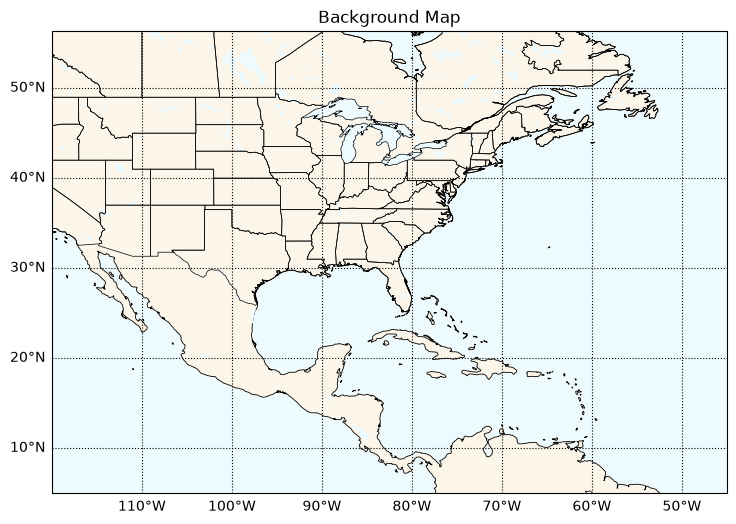

In [10]:
# The plt.figure object is the Matplotlib container that holds all inner elements, including the plotting area (map).
plt.figure(figsize=(12,6)) # width, height (inches)

# set the map projection and map extent
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-45, -120, 5, 50])

# add features and customize their style
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=.6)
ax.add_feature(cfeature.OCEAN.with_scale('50m'), color='#EDFBFF')
ax.add_feature(cfeature.LAND.with_scale('50m'), color='#FBF5EA')
ax.add_feature(cfeature.LAKES.with_scale('50m'), color='#EDFBFF')
ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=.5)

# show grid lines and labels, hide the lables on the top and right of the map (which are also drawn by Matplotlib by default)
gls = ax.gridlines(draw_labels=True, linestyle='dotted', color='black')
gls.top_labels=False   # suppress top labels
gls.right_labels=False # suppress right labels

# add a map title
ax.set_title('Background Map')

plt.show()


The first line of code is creating a new figure object with a specified size. The `plt.figure(figsize=(12,6))` function call is creating a new figure object with a width of 12 inches and a height of 6 inches. This figure object is the container that holds all elements of the plot, including the plotting area (map).

The next two lines of code are setting the map projection and extent. The `plt.axes(projection=ccrs.PlateCarree())` function call is setting the map projection to Plate Carrée. The `ax.set_extent([-45, -120, 5, 50])` function call is setting the map extent to the coordinates -45 to -120 on the x-axis (longitude) and 5 to 50 on the y-axis (latitude).

The following lines of code are adding various features to the map and customizing their styles. The `ax.add_feature(cfeature.<FEATURE>.with_scale('50m'), <STYLE>)` function calls are adding the specified features to the map with a resolution of 50 meters and the specified styles. The features being added are:

- Coastline: This will draw the outline of continents and major islands on the map with a line width of 0.6.
- Ocean: This will color the ocean areas on the map with the color '#EDFBFF'.
- Land: This will color the land areas on the map with the color '#FBF5EA'.
- Lakes: This will draw the major lakes on the map with the color '#EDFBFF'.
- States: This will draw the U.S. state borders on the map with a line width of 0.5.

The next lines of code are adding gridlines and labels to the map and suppressing the labels on the top and right of the map. The `ax.gridlines(draw_labels=True, linestyle='dotted', color='black')` function call is adding gridlines to the map with labels, a dotted line style, and a black color. The `gls.top_labels=False` and `gls.right_labels=False` lines of code are suppressing the labels on the top and right of the map.

The next line of code is setting the title of the map. The `ax.set_title('Background Map')` function call is setting the title of the map to 'Background Map'.

# Part 3: How to get data on the map

As an example, we will use the comma-separated text file with three water level stations that we previously fetched. The file contains the station ID and the coordinates (lat/lon) of each point.

| station_id | lat       | lon        |
|------------|-----------|------------|
| 8760721    | 29.179306 | -89.258833 |
| 8670870    | 32.034694 | -80.903028 |
| 02251800   | 27.754473 | -80.427552 |

## 3.1 - Importing the CSV file

A csv file can be opened and read with different methods. For exploring and handling our data we will use the library `pandas` which is a powerful Python data analysis and manipulation tool. We have imported the pandas library with the alias name `pd`.

Pandas converts the input data to a DataFrame which is a two-dimensional, heterogeneous tabular data format (rows/columns). The commonly practiced designation for a pandas variable name is `df_<some name>`, where `df` stands for DataFrame. However you can name your variable in any other way, too.


In [11]:
# read the csv input file
df_stations = pd.read_csv('water_level_stations.csv')

## 3.2 - Exploring the Pandas data frame

In [12]:
# get a general print of the contained data
df_stations.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   station_id  3 non-null      int64  
 1   lat         3 non-null      float64
 2   lon         3 non-null      float64
dtypes: float64(2), int64(1)
memory usage: 204.0 bytes


This is the output of the `info()` method called on a pandas DataFrame object. The `info()` method provides a concise summary of the DataFrame. Here's what each part of the output means:

- `<class 'pandas.core.frame.DataFrame'>`: This is the type of the object, which is a pandas DataFrame.

- `RangeIndex: 3 entries, 0 to 2`: This is the index of the DataFrame. It's a RangeIndex, which is a type of index that is a pure integer-based index. The DataFrame has 3 entries (rows) numbered from 0 to 2.

- `Data columns (total 3 columns)`: This indicates that the DataFrame has a total of 3 columns.

- The next three lines are a summary of each column in the DataFrame:

  - `#   Column      Non-Null Count  Dtype`: This is the header of the column summary. It shows the column number (#), the column name (Column), the number of non-null values in the column (Non-Null Count), and the data type of the column (Dtype).
  
  - `0   station_id  3 non-null      int64`: This is the summary for the first column (column number 0). The column name is 'station_id', it has 3 non-null values, and the data type is int64 (64-bit integer).
  
  - `1   lat         3 non-null      float64`: This is the summary for the second column (column number 1). The column name is 'lat', it has 3 non-null values, and the data type is float64 (64-bit floating point number).
  
  - `2   lon         3 non-null      float64`: This is the summary for the third column (column number 2). The column name is 'lon', it has 3 non-null values, and the data type is float64.

- `dtypes: float64(2), int64(1)`: This is a summary of the data types in the DataFrame. There are 2 columns with the float64 data type and 1 column with the int64 data type.

- `memory usage: 204.0 bytes`: This is the amount of memory used by the DataFrame.

## 3.3 - Mapping the point data

In order to map the points with Cartopy/Matplotlib, we need to assign the lon/lat values that belong to each station. We therefore access the two colums in the pandas DataFrame that hold the longitude and latitude values.
 - `[:]` retrieves all values in the data set. 
 - The returned values are by default `Numpy arrays`, so we can directly use them for the Matplotlib plot.

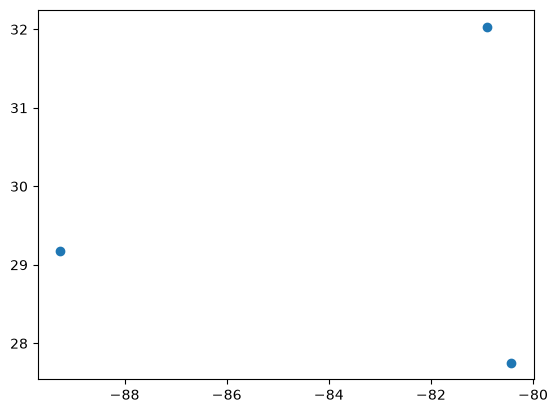

In [13]:
# retrieve the lon/lat values
lon = df_stations['lon'][:]
lat = df_stations['lat'][:]

# we can use the Matplotlb 'plot' or 'scatter' function to draw the coordinate pairs as points
plt.plot(lon, lat, marker='o', linewidth=0)

plt.show()

The function `plt.plot()` draws the coordiante pairs (lon/lat) as markers (points) on the map. the marker style is a circle designated as 'o'. Matplotlib connects the points with a line by default. We are hiding the line by setting the line width to '0'.

## 3.4 - Adding the points to the background map

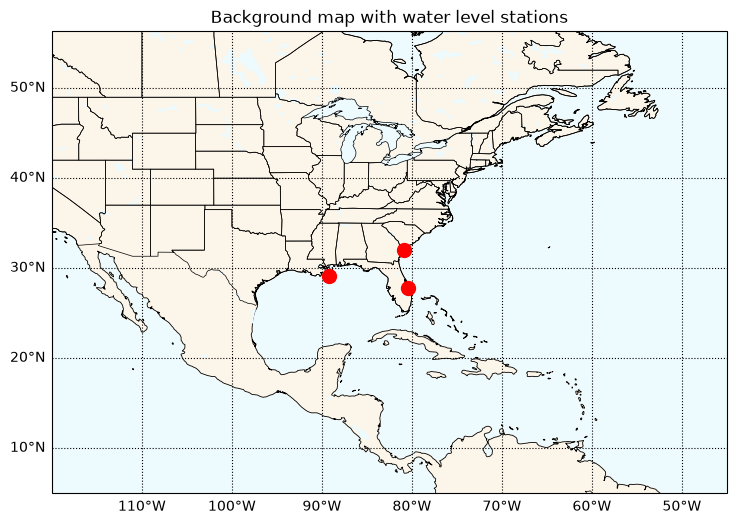

In [14]:
# The plt.figure object is the Matplotlib container that holds all inner elements, including the plotting area (map).
# set the plot (figure) size
plt.figure(figsize=(12,6)) # width, height (inches)

# set the map projection and map extent
ax = plt.axes(projection=ccrs.PlateCarree())
ax.set_extent([-45, -120, 5, 50])

# add features and customize their style
ax.add_feature(cfeature.COASTLINE.with_scale('50m'), linewidth=.6)
ax.add_feature(cfeature.OCEAN.with_scale('50m'), color='#EDFBFF')
ax.add_feature(cfeature.LAND.with_scale('50m'), color='#FBF5EA')
ax.add_feature(cfeature.LAKES.with_scale('50m'), color='#EDFBFF')
ax.add_feature(cfeature.STATES.with_scale('50m'), linewidth=.5)

# show grid lines and labels, hide the labels on the top and right of the map (which are drawn by Matplotlib by default)
gls = ax.gridlines(draw_labels=True, linestyle='dotted', color='black')
gls.top_labels=False   # suppress top labels
gls.right_labels=False # suppress right labels

# add a map title
ax.set_title('Background map with water level stations')

# we can use the Matplotlb 'plot' or 'scatter' function to draw the coordinate pairs as points
# draw the points as red circles and with a larger size
plt.plot(lon, lat, color='r', marker='o', markersize=10, linewidth=0)
#plt.scatter(lon, lat, color='r', marker='o', edgecolors='k', s=120, alpha=1.0)

plt.show()

We use our background map as customized in the previous steps. We then simply draw the points on top of the map by calling the `plt.plot()` function. In this example, we are using a red color (color='r') and a larger point size (markersize=10).

## 3.5 - Limiting the map  extent to the area of interest and adding point labels

If we want to dynamically limit our map to the region that contains the water level stations (points), we can do so by using the Matplotlib function `xlim/ylim`. We won't need to set a map extent in that case.

Finally, we will increase the resolution of our background map features to '10m', add labels to our points showing the station ID for each station, and annotate the map with a logo and a text. Note: If you are using a static map (with always the same map extent), you can also add the logo/text to the background map.

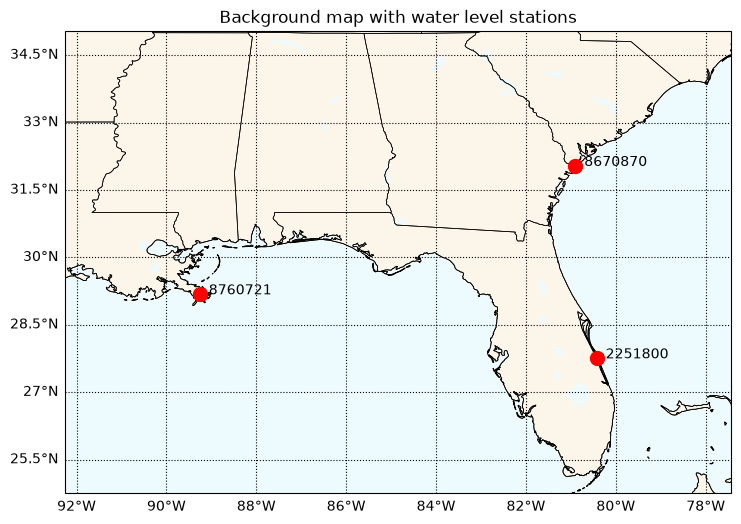

In [20]:
# The plt.figure object is the Matplotlib container that holds all inner elements, including the plotting area (map).
# set the plot (figure) size
plt.figure(figsize=(12,6)) # width, height (inches)
# set the map projection and map extent
ax = plt.axes(projection=ccrs.PlateCarree())

# add features and customize their style
ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=.6)
ax.add_feature(cfeature.OCEAN.with_scale('10m'), color='#EDFBFF')
ax.add_feature(cfeature.LAND.with_scale('10m'), color='#FBF5EA')
ax.add_feature(cfeature.LAKES.with_scale('10m'), color='#EDFBFF')
ax.add_feature(cfeature.STATES.with_scale('10m'), linewidth=.5)

# show grid lines and labels, hide the lables on the top and right of the map (which are drawn by Matplotlib by default)
gls = ax.gridlines(draw_labels=True, linestyle='dotted', color='black')
gls.top_labels=False   # suppress top labels
gls.right_labels=False # suppress right labels

# add a map title
ax.set_title('Background map with water level stations')


# draw the points as red circles and with a larger size
plt.plot(lon, lat, color='r', marker='o', markersize=10, linewidth=0)

# add labels with the station ID; move the labels to the right so that they do not overlap the marker icon
station_id = df_stations['station_id'][:]
for i, txt in enumerate(station_id):
  ax.annotate(txt, (lon[i]+0.2, lat[i]))

# limit the extent to the bounding box of the data points and apply some offsets to each side
plt.xlim((lon.min()-3, lon.max()+3))
plt.ylim((lat.min()-3, lat.max()+3))


# add a logo and annotation text
# create an imagebox that holds the image and sets the zoom level
with urllib.request.urlopen('https://coastalrisk.live/wp-content/uploads/2018/05/cera_50x50.png') as url:
    logo = np.array(Image.open(url))
imagebox = OffsetImage(logo, zoom = 0.5)
# create annotation containers that hold the logo and text, use map coordinates for positioning the top-left corner of the boxes
ab_img = AnnotationBbox(imagebox, (lon.min()-0.6,lat.max()+0.6), bboxprops =dict(edgecolor='None'), frameon=False)
ab_text = AnnotationBbox(TextArea("cera.coastalrisk.live"), (lon.min()+0.75,lat.max()+0.6)) 
# draw the annotation boxes
#ax.add_artist(ab_img)
#ax.add_artist(ab_text)

plt.savefig('outputs/cartopy/cartopy.png', dpi=300, bbox_inches='tight')
plt.show()

For creating the labels, we are fetching the column `station_id` from the pandas dataframe. We are then assigning the individual 'station_id' values as variable `txt` to each station by looping through all stations and getting the `lon/lat` values. We are also adding a small padding (0.2 in map coordinates) to move the labels to the right so that they do not overlap with the marker icon.

For details on how to add logos/annotations to the plot, plese refer to the Matplotlib documentation.

# Part 4: Extra interactive map

## 4.1 - Defining the map and the parameters

In [16]:
def plot_map(lon_center=-90.0, lat_center=20.0, distance=34.0):
    plt.figure(figsize=(18,12)) # width, height (inches)
    ax = plt.axes(projection=ccrs.PlateCarree())
    ax.add_feature(cfeature.COASTLINE.with_scale('10m'), linewidth=.6)
    ax.add_feature(cfeature.OCEAN.with_scale('10m'))
    ax.add_feature(cfeature.LAND.with_scale('10m'), color='#FBF5EA')
    ax.add_feature(cfeature.LAKES.with_scale('10m'))
    ax.add_feature(cfeature.STATES.with_scale('10m'), linewidth=.5)
    ax.add_feature(cfeature.RIVERS.with_scale('10m'), linewidth=.5)
    gls = ax.gridlines(draw_labels=True, linestyle='dotted', color='black')
    gls.top_labels=False
    gls.right_labels=False
    ax.set_title('Change the map extent by selecting a distance (in deg) that is added to the center point')

    # Draw crosshair
    ax.axhline(lat_center, color='red', linewidth=1)
    ax.axvline(lon_center, color='red', linewidth=1)

    plt.xlim((lon_center-distance, lon_center+distance))
    plt.ylim((lat_center-distance, lat_center+distance))
    plt.show()


## 4.2 - Generating the interactive map

In [17]:
interact(plot_map, 
     lon_center=FloatSlider(min=-100.0, max=-70.0, step=0.1, value=-91.0, layout=Layout(width='500px')), 
     lat_center=FloatSlider(min=10.0, max=25.0, step=0.1, value=20.0, layout=Layout(width='500px')), 
     distance=FloatSlider(min=13.0, max=70.0, step=0.3, value=34.0, layout=Layout(width='500px'))
)

interactive(children=(FloatSlider(value=-91.0, description='lon_center', layout=Layout(width='500px'), max=-70…

<function __main__.plot_map(lon_center=-90.0, lat_center=20.0, distance=34.0)>